## Linear Quantization

In [58]:
import numpy as np
import matplotlib.pyplot as plt

# Simulate original float values (e.g., model weights)
x= np.linspace(-1, 1, 100)
x[:10]

array([-1.        , -0.97979798, -0.95959596, -0.93939394, -0.91919192,
       -0.8989899 , -0.87878788, -0.85858586, -0.83838384, -0.81818182])

In [59]:
# Define quantization parameters
qunatized_bits=8

min_x = -1.0
max_x = 1.0

qmin = 2**(qunatized_bits-1) * -1
qmax = 2**(qunatized_bits-1) - 1

print(qmin, qmax)

# Calculate scale and zero-point for symmetric quantization
scale = (max_x - min_x) / (qmax - qmin) # step size
scale

-128 127


0.00784313725490196

In [60]:
zero_point = 0  # For symmetric quantization, zero-point is typically 0

# Quantize the values: float to int8
quantized_x = np.round((x - zero_point) / scale).astype(np.int8)

# Clip the quantized values to ensure they are within the valid range
quantized_x = np.clip(quantized_x, qmin, qmax)

print(quantized_x[:10])


[-128 -125 -122 -120 -117 -115 -112 -109 -107 -104]


In [61]:
# Dequantize the values: int8 back to float
dequantized_x = quantized_x * scale + zero_point
print(dequantized_x[:10])

[-1.00392157 -0.98039216 -0.95686275 -0.94117647 -0.91764706 -0.90196078
 -0.87843137 -0.85490196 -0.83921569 -0.81568627]


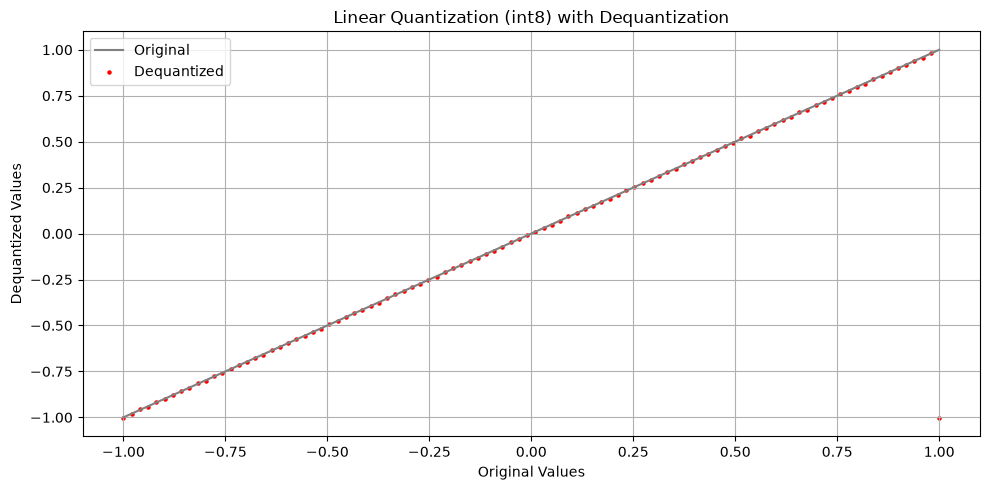

In [62]:
# Plotting the original vs dequantized values
plt.figure(figsize=(10, 5))
plt.plot(x, x, label='Original', linestyle='-', color='grey')
plt.scatter(x, dequantized_x, label='Dequantized', color='red', s=5)
plt.title("Linear Quantization (int8) with Dequantization")
plt.xlabel("Original Values")
plt.ylabel("Dequantized Values")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## NF4 (Normal Float 4) Quantization

In [68]:
import numpy as np
import matplotlib.pyplot as plt

In [69]:
# Step 1: Define 16 NF4 respresentation float values
# These are example NF4 values (manually chosen to mimic a Gaussian distribution)
# In practice, libraries like `transformers` or `bitsandbytes` would handle this automatically.
nf4_values = np.array([
    -1.0, -0.75, -0.5, -0.35, -0.2, -0.1, -0.05, -0.01,
    0.01, 0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1.0
])

# Step 2: Simulate original float values (e.g., model weights)
x = np.linspace(-1, 1, 100)
x[:10]

array([-1.        , -0.97979798, -0.95959596, -0.93939394, -0.91919192,
       -0.8989899 , -0.87878788, -0.85858586, -0.83838384, -0.81818182])

In [70]:
# Step 3: Quantize the original values to nearest NF4 values
def quantize_to_nf4(x_vals, nf4_lut):
    # Find the nearest NF4 value for each original value
    quantized_indices = np.argmin(np.abs(x_vals[:, None] - nf4_lut[None, :]), axis=1)
    quantized_values = nf4_lut[quantized_indices]
    return quantized_values

x_nf4 = quantize_to_nf4(x, nf4_values)
x_nf4[:10]

array([-1.  , -1.  , -1.  , -1.  , -1.  , -1.  , -1.  , -0.75, -0.75,
       -0.75])

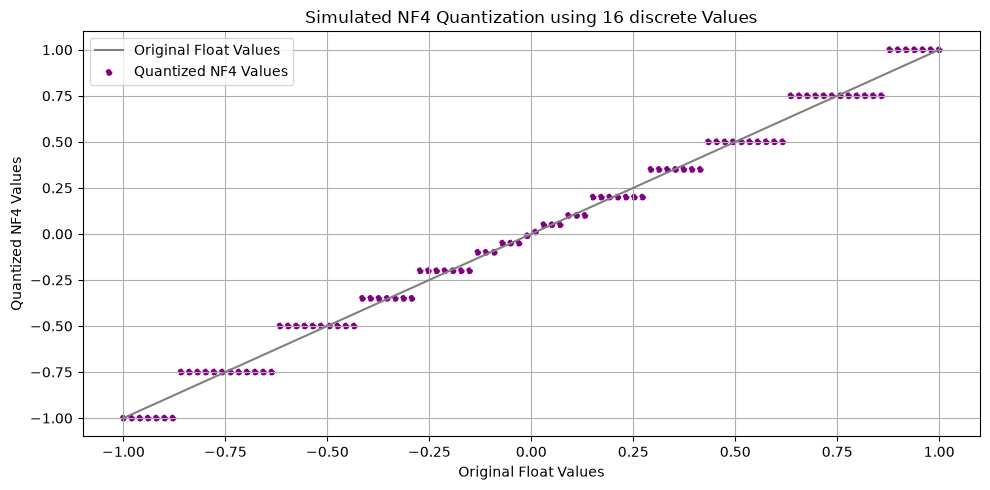

In [73]:
# Step 4: Plot original vs quantized NF4 values
plt.figure(figsize=(10, 5))
plt.plot(x,x, label='Original Float Values', linestyle='-', color='grey')
plt.scatter(x,x_nf4, label='Quantized NF4 Values', linestyle='--', color='purple', s=15)
plt.title('Simulated NF4 Quantization using 16 discrete Values')
plt.xlabel('Original Float Values')
plt.ylabel('Quantized NF4 Values')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()